#Import Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
import warnings
warnings.filterwarnings('ignore')

In [ ]:
# Set style untuk visualisasi
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

In [ ]:
# Path dataset
dataset_path = "/content/fraud_dataset.csv"
data = pd.read_csv(dataset_path)
data.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0.0,0.0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0.0,0.0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1.0,0.0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1.0,0.0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0.0,0.0


In [ ]:
data.tail()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
83556,10,PAYMENT,7705.70,C1834114901,96490.0,88784.30,M1214836727,0.00,0.00,0.0,0.0
83557,10,CASH_OUT,319045.01,C1964329082,56471.0,0.00,C699133054,0.00,319045.01,0.0,0.0
83558,10,CASH_IN,249169.96,C1421944154,3481.0,252650.96,C790672270,38177.07,0.00,0.0,0.0
83559,10,CASH_OUT,244279.64,C722886752,29968.0,0.00,C1492538502,25680.00,269959.64,0.0,0.0
83560,10,CASH_OUT,145014.63,C60491101,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
# Tampilkan informasi dataset
print("=" * 60)
print("INFORMASI DATASET")
print("=" * 60)
print(f"Shape dataset: {data.shape}")
print(f"Jumlah baris: {data.shape[0]:,}")
print(f"Jumlah kolom: {data.shape[1]}")

print(data.info())
print(data.describe())

INFORMASI DATASET
Shape dataset: (83561, 11)
Jumlah baris: 83,561
Jumlah kolom: 11
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 83561 entries, 0 to 83560
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   step            83561 non-null  int64  
 1   type            83561 non-null  object 
 2   amount          83561 non-null  float64
 3   nameOrig        83561 non-null  object 
 4   oldbalanceOrg   83560 non-null  float64
 5   newbalanceOrig  83560 non-null  float64
 6   nameDest        83560 non-null  object 
 7   oldbalanceDest  83560 non-null  float64
 8   newbalanceDest  83560 non-null  float64
 9   isFraud         83560 non-null  float64
 10  isFlaggedFraud  83560 non-null  float64
dtypes: float64(7), int64(1), object(3)
memory usage: 7.0+ MB
None
               step        amount  oldbalanceOrg  newbalanceOrig  \
count  83561.000000  8.356100e+04   8.356000e+04    8.356000e+04   
mean       8.204473 

In [ ]:
# Cek missing values
print("\nMissing values per kolom:")
missing = data.isnull().sum()
missing_percent = (missing / len(data)) * 100
missing_df = pd.DataFrame({
        'Missing Count': missing,
        'Missing %': missing_percent
    })

print(missing_df[missing_df['Missing Count'] > 0])

if missing.sum() == 0:
  print("✓ Tidak ada missing values")


Missing values per kolom:
                Missing Count  Missing %
oldbalanceOrg               1   0.001197
newbalanceOrig              1   0.001197
nameDest                    1   0.001197
oldbalanceDest              1   0.001197
newbalanceDest              1   0.001197
isFraud                     1   0.001197
isFlaggedFraud              1   0.001197


In [ ]:
# Cek jumlah nilai kosong per kolom
data.isnull().sum()

,0
step,0
type,0
amount,0
nameOrig,0
oldbalanceOrg,1
newbalanceOrig,1
nameDest,1
oldbalanceDest,1
newbalanceDest,1
isFraud,1


In [ ]:
# Cek duplikat
duplicates = data.duplicated().sum()
print(f"\nJumlah data duplikat: {duplicates}")
if duplicates > 0:
  print(f"Persentase duplikat: {(duplicates/len(data))*100:.2f}%")
else:
  print("✓ Tidak ada data duplikat")


Jumlah data duplikat: 0
✓ Tidak ada data duplikat


In [ ]:
# Simpan informasi untuk digunakan nanti
dataset_info = {
        'shape': data.shape,
        'columns': list(data.columns),
        'dtypes': data.dtypes.to_dict(),
        'missing_values': missing.to_dict(),
        'duplicates': duplicates
    }

#Exploratory Data Analysis (EDA)

In [ ]:
data['type'].value_counts()

,count
type,
PAYMENT,33529
CASH_OUT,25156
CASH_IN,16818
TRANSFER,7192
DEBIT,866


In [ ]:
# Calculate value counts for the 'type' column
type_counts = data['type'].value_counts()

# Create a bar plot using Plotly Express
fig = px.bar(x=type_counts.index, y=type_counts.values, labels={'x': 'Transaction Type', 'y': 'Count'}, title='Transaction Type Distribution')

# Show the plot
fig.show()

In [ ]:
from sklearn.preprocessing import LabelEncoder

data_encoded = data.copy()
categorical_cols = data_encoded.select_dtypes(include=['object', 'category']).columns.tolist()

cols_to_encode = []
for col in categorical_cols:
    if col not in ['nameOrig', 'nameDest', 'isFraud']:
        cols_to_encode.append(col)
        print(f"  - {col}: {data_encoded[col].nunique()} unique values")

# Label encoding
label_encoders = {}
for col in cols_to_encode:
    le = LabelEncoder()
    data_encoded[col] = le.fit_transform(data_encoded[col].astype(str))
    label_encoders[col] = le

print(f"Shape: {data_encoded.shape}")
print("Tipe data baru:")
print(data_encoded.dtypes)

  - type: 5 unique values
Shape: (83561, 11)
Tipe data baru:
step                int64
type                int64
amount            float64
nameOrig           object
oldbalanceOrg     float64
newbalanceOrig    float64
nameDest           object
oldbalanceDest    float64
newbalanceDest    float64
isFraud           float64
isFlaggedFraud    float64
dtype: object


Kolom numerik yang akan digunakan: ['step', 'type', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'isFraud', 'isFlaggedFraud']

Korelasi dengan isFraud (diurutkan dari tertinggi):
isFraud           1.000000
amount            0.041582
type              0.016320
oldbalanceOrg    -0.004387
newbalanceDest   -0.007017
oldbalanceDest   -0.010200
newbalanceOrig   -0.011580
step             -0.051344
isFlaggedFraud         NaN
Name: isFraud, dtype: float64


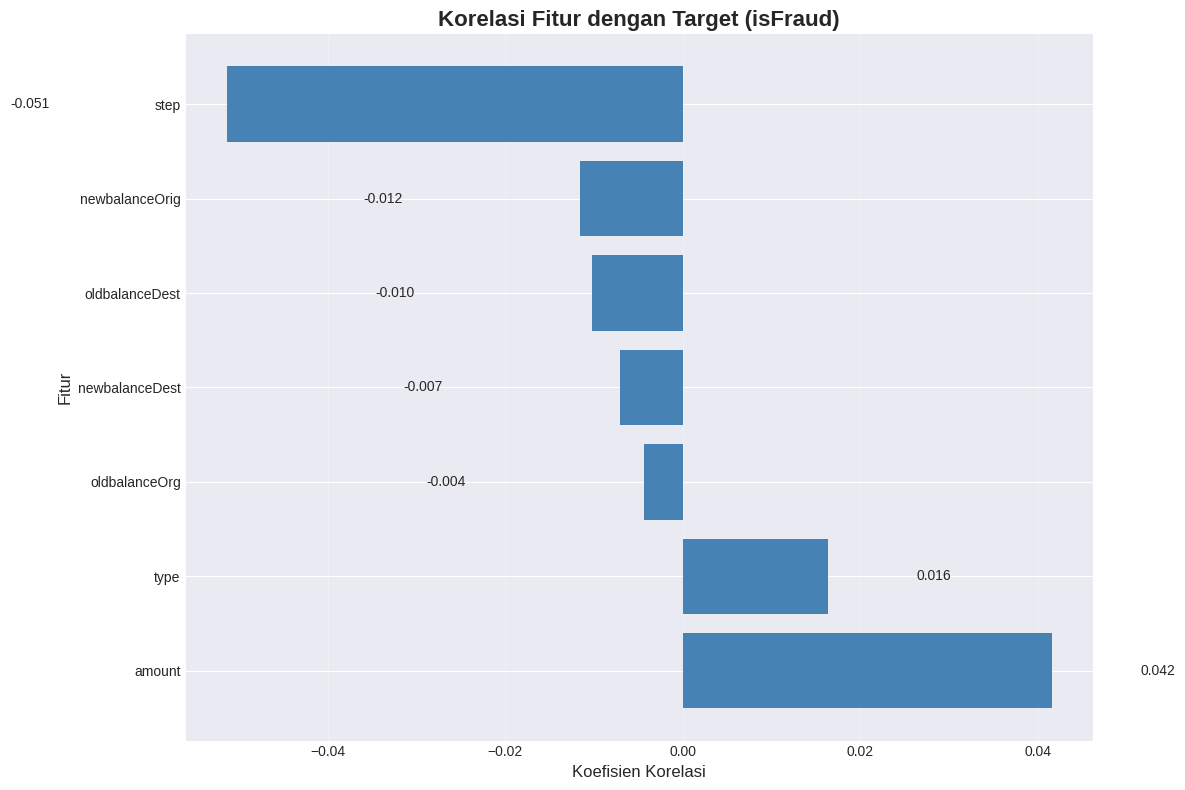

In [ ]:
# Hitung korelasi dengan parameter numeric_only
numeric_cols = data_encoded.select_dtypes(include=[np.number]).columns
print(f"Kolom numerik yang akan digunakan: {list(numeric_cols)}")

# Hitung korelasi
correlation = data_encoded[numeric_cols].corr()

print("\nKorelasi dengan isFraud (diurutkan dari tertinggi):")
fraud_correlation = correlation["isFraud"].sort_values(ascending=False)
print(fraud_correlation)

# Buat dataframe untuk visualisasi
corr_df = pd.DataFrame({
    'Feature': fraud_correlation.index,
    'Correlation': fraud_correlation.values
})

# Filter out isFraud
corr_df = corr_df[corr_df['Feature'] != 'isFraud']

# Plot barchart korelasi dengan isFraud
plt.figure(figsize=(12, 8))
bars = plt.barh(corr_df['Feature'], corr_df['Correlation'], color='steelblue')
plt.title('Korelasi Fitur dengan Target (isFraud)', fontsize=16, fontweight='bold')
plt.xlabel('Koefisien Korelasi', fontsize=12)
plt.ylabel('Fitur', fontsize=12)
plt.grid(axis='x', alpha=0.3)

# Tambahkan nilai korelasi di setiap bar
for bar, corr in zip(bars, corr_df['Correlation']):
    width = bar.get_width()
    plt.text(width + (0.01 if width >= 0 else -0.02),
             bar.get_y() + bar.get_height()/2,
             f'{corr:.3f}',
             ha='left' if width >= 0 else 'right',
             va='center',
             fontsize=10)

plt.tight_layout()
plt.show()

In [ ]:
data["type"] = data["type"].map({
    "CASH_OUT": 1,
    "PAYMENT": 2,
    "CASH_IN": 3,
    "TRANSFER": 4,
    "DEBIT": 5
})

data["isFraud"] = data["isFraud"].map({
    0: "No Fraud",
    1: "Fraud"
})

data.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,2,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,No Fraud,0.0
1,1,2,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,No Fraud,0.0
2,1,4,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,Fraud,0.0
3,1,1,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,Fraud,0.0
4,1,2,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,No Fraud,0.0


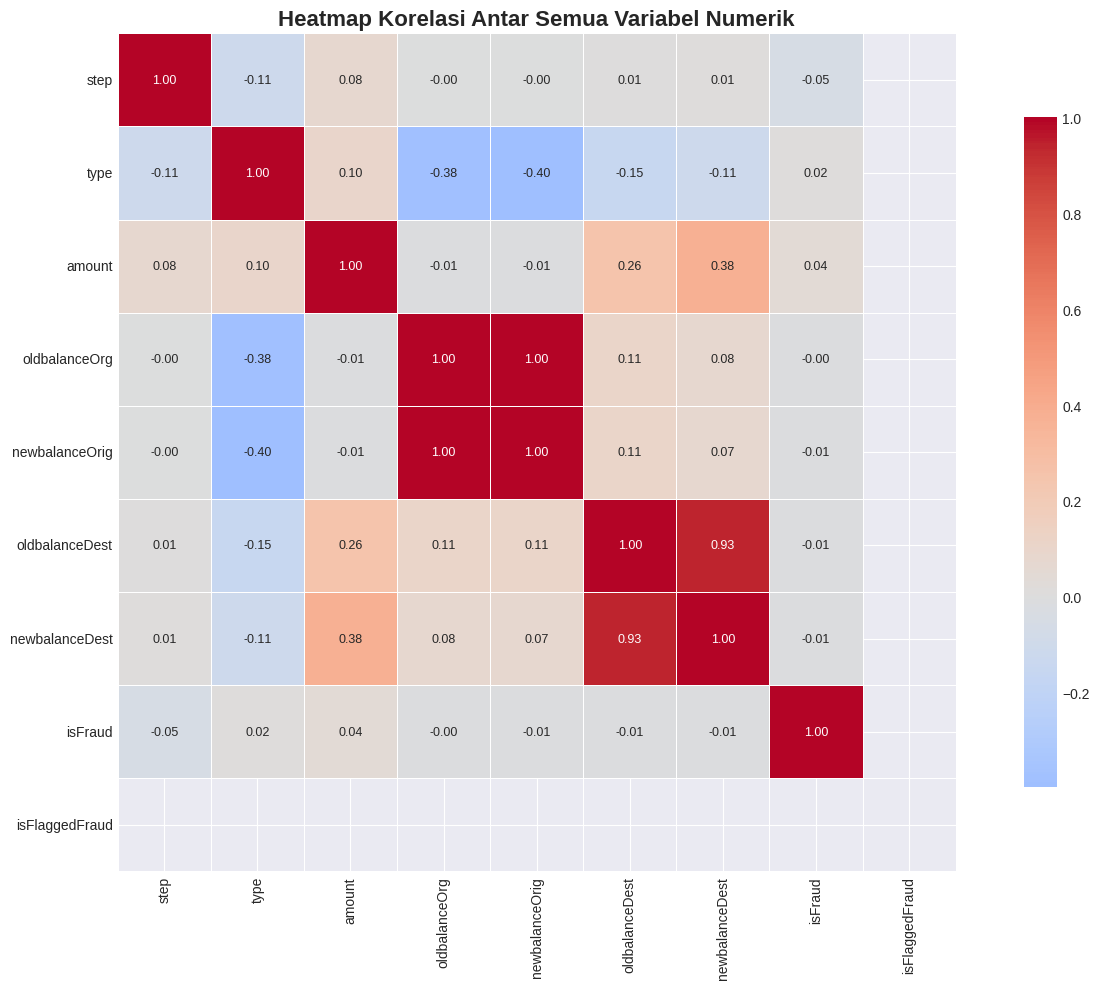

In [ ]:
# Heatmap korelasi lengkap
plt.figure(figsize=(14, 10))
sns.heatmap(correlation, annot=True, cmap='coolwarm', center=0,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8},
            fmt='.2f', annot_kws={'size': 9})
plt.title('Heatmap Korelasi Antar Semua Variabel Numerik', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()


Top feature dengan korelasi positif tertinggi: amount

Fitur dengan korelasi POSITIF tertinggi dengan isFraud:
  - amount: 0.0416
  - type: 0.0163


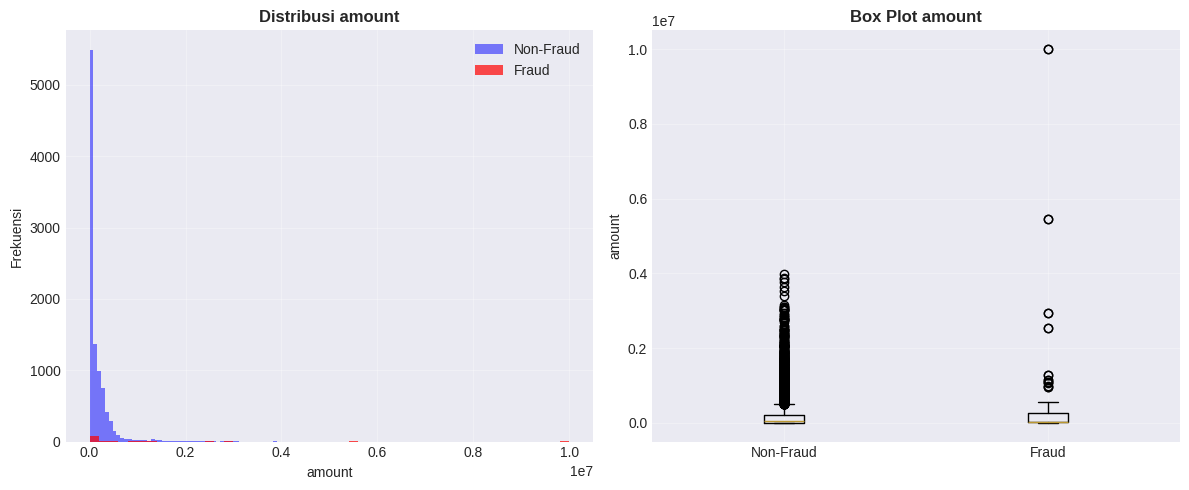


Fitur dengan korelasi NEGATIF tertinggi dengan isFraud:
  - oldbalanceOrg: -0.0044
  - newbalanceDest: -0.0070
  - oldbalanceDest: -0.0102
  - newbalanceOrig: -0.0116
  - step: -0.0513


In [ ]:
# Fitur dengan korelasi positif tertinggi (selain isFraud itu sendiri)
positive_corr = fraud_correlation[fraud_correlation.index != 'isFraud']
positive_corr = positive_corr[positive_corr > 0]
top_feature = positive_corr.sort_values(ascending=False).index[0]
print(f"\nTop feature dengan korelasi positif tertinggi: {top_feature}")

if len(positive_corr) > 0:
    print(f"\nFitur dengan korelasi POSITIF tertinggi dengan isFraud:")
    for feature, corr_value in positive_corr.head(5).items():
        print(f"  - {feature}: {corr_value:.4f}")

    # Visualisasi hubungan dengan isFraud
    if data_encoded[top_feature].nunique() <= 10:
        # Jika kategorikal (setelah encoding)
        fraud_by_feature = data_encoded.groupby(top_feature)['isFraud'].mean() * 100
        plt.figure(figsize=(10, 6))
        bars = plt.bar(fraud_by_feature.index.astype(str), fraud_by_feature.values, color='red', alpha=0.7)
        plt.title(f'Fraud Rate berdasarkan {top_feature}', fontsize=14, fontweight='bold')
        plt.xlabel(top_feature, fontsize=12)
        plt.ylabel('Fraud Rate (%)', fontsize=12)

        # Tambah nilai di atas bar
        for bar, rate in zip(bars, fraud_by_feature.values):
            plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                    f'{rate:.2f}%', ha='center', va='bottom', fontsize=10)

        plt.tight_layout()
        plt.show()
    else:
        # Jika numerik kontinu
        plt.figure(figsize=(12, 5))

        # Histogram untuk fraud dan non-fraud
        plt.subplot(1, 2, 1)
        fraud_data = data_encoded[data_encoded['isFraud'] == 1][top_feature]
        # PERBAIKAN: Definisikan non_fraud_data sebelum digunakan
        all_non_fraud_data = data_encoded[data_encoded['isFraud'] == 0][top_feature]
        sample_size = min(10000, len(all_non_fraud_data))
        non_fraud_data = all_non_fraud_data.sample(sample_size, random_state=42)

        plt.hist(non_fraud_data, bins=50, alpha=0.5, label='Non-Fraud', color='blue')
        plt.hist(fraud_data, bins=50, alpha=0.7, label='Fraud', color='red')
        plt.title(f'Distribusi {top_feature}', fontsize=12, fontweight='bold')
        plt.xlabel(top_feature, fontsize=10)
        plt.ylabel('Frekuensi', fontsize=10)
        plt.legend()
        plt.grid(alpha=0.3)

        # Box plot
        plt.subplot(1, 2, 2)
        box_data = [non_fraud_data, fraud_data]
        plt.boxplot(box_data, labels=['Non-Fraud', 'Fraud'])
        plt.title(f'Box Plot {top_feature}', fontsize=12, fontweight='bold')
        plt.ylabel(top_feature, fontsize=10)
        plt.grid(alpha=0.3)

        plt.tight_layout()
        plt.show()

# Fitur dengan korelasi negatif
negative_corr = fraud_correlation[fraud_correlation < 0]
if len(negative_corr) > 0:
    print(f"\nFitur dengan korelasi NEGATIF tertinggi dengan isFraud:")
    for feature, corr_value in negative_corr.head(5).items():
        print(f"  - {feature}: {corr_value:.4f}")

# Feature Engineering

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
import warnings
warnings.filterwarnings('ignore')

# Copy data hasil encoding sebelumnya
data_fe = data_encoded.copy()

print("Shape awal:", data_fe.shape)

Shape awal: (83561, 11)


In [ ]:
# Feature Interaksi

# Perubahan balance
data_fe['balance_change_org'] = data_fe['newbalanceOrig'] - data_fe['oldbalanceOrg']
data_fe['balance_change_dest'] = data_fe['newbalanceDest'] - data_fe['oldbalanceDest']
data_fe['balance_change_total'] = data_fe['balance_change_org'] + data_fe['balance_change_dest']

# Rasio amount terhadap balance awal
data_fe['amount_balance_ratio'] = data_fe['amount'] / (data_fe['oldbalanceOrg'] + 1)

# Flag balance nol
data_fe['is_zero_balance_after'] = (data_fe['newbalanceOrig'] == 0).astype(int)
data_fe['is_zero_balance_before'] = (data_fe['oldbalanceOrg'] == 0).astype(int)

# Log transform untuk amount
data_fe['amount_log'] = np.log1p(data_fe['amount'])
data_fe['amount_log'].replace([np.inf, -np.inf], np.nan, inplace=True)

# Kategori amount
bins = [0, 1000, 10000, 50000, 200000, np.inf]
labels = [1, 2, 3, 4, 5]
data_fe['amount_category'] = pd.cut(data_fe['amount'], bins=bins, labels=labels)
data_fe['amount_category'] = pd.to_numeric(data_fe['amount_category'], errors='coerce')

# Domain Knowledge

# Pola mencurigakan
data_fe['is_transfer_to_self'] = (data_fe['nameOrig'] == data_fe['nameDest']).astype(int)
data_fe['is_large_transaction'] = (data_fe['amount'] > data_fe['oldbalanceOrg'] * 0.9).astype(int)
data_fe['is_round_amount'] = (data_fe['amount'] % 1000 == 0).astype(int)

# Time-based features
data_fe['hour_of_day'] = data_fe['step'] % 24
data_fe['is_night_time'] = ((data_fe['hour_of_day'] >= 22) | (data_fe['hour_of_day'] <= 6)).astype(int)
data_fe['is_business_hours'] = ((data_fe['hour_of_day'] >= 9) & (data_fe['hour_of_day'] <= 17)).astype(int)

# Transaction type dummies
if 'type' in data.columns:
    type_dummies = pd.get_dummies(data['type'], prefix='type')
else:
    type_dummies = pd.get_dummies(data_fe['type'], prefix='type')

data_fe = pd.concat([data_fe, type_dummies], axis=1)

# Fitur Statistik

# Z-score
mean_amt = data_fe['amount'].mean()
std_amt = data_fe['amount'].std()
data_fe['amount_zscore'] = (data_fe['amount'] - mean_amt) / (std_amt + 1e-10)

# Percentile
data_fe['amount_percentile'] = data_fe['amount'].rank(pct=True)
data_fe['balance_org_percentile'] = data_fe['oldbalanceOrg'].rank(pct=True)

# Rasio tambahan
data_fe['balance_org_dest_ratio'] = np.where(
    data_fe['oldbalanceDest'] == 0,
    np.nan,
    data_fe['oldbalanceOrg'] / (data_fe['oldbalanceDest'] + 1e-10)
)

data_fe['transaction_to_balance_ratio'] = np.where(
    (data_fe['oldbalanceOrg'] + data_fe['oldbalanceDest']) == 0,
    np.nan,
    data_fe['amount'] / (data_fe['oldbalanceOrg'] + data_fe['oldbalanceDest'] + 1e-10)
)

# Fitur Tambahan untuk Fraud Detection

data_fe['error_balance_org'] = data_fe['amount'] - data_fe['balance_change_org'].abs()
data_fe['error_balance_dest'] = data_fe['amount'] - data_fe['balance_change_dest'].abs()

data_fe['is_error_transaction'] = (
    (data_fe['error_balance_org'].abs() > 1) |
    (data_fe['error_balance_dest'].abs() > 1)
).astype(int)

# Flag lain
data_fe['is_high_amount'] = (data_fe['amount'] > data_fe['amount'].quantile(0.99)).astype(int)
data_fe['is_low_amount']  = (data_fe['amount'] < data_fe['amount'].quantile(0.01)).astype(int)

In [ ]:
# Handle Missing Values

for col in data_fe.columns:
    if data_fe[col].dtype in ['float64', 'int64'] and data_fe[col].isnull().any():
        fill_value = data_fe[col].median()
        data_fe[col].fillna(fill_value, inplace=True)
        print(f"  -> {col}: diisi median ({fill_value:.2f})")

  -> oldbalanceOrg: diisi median (19873.00)
  -> newbalanceOrig: diisi median (0.00)
  -> oldbalanceDest: diisi median (19389.16)
  -> newbalanceDest: diisi median (36855.93)
  -> isFraud: diisi median (0.00)
  -> isFlaggedFraud: diisi median (0.00)
  -> balance_change_org: diisi median (0.00)
  -> balance_change_dest: diisi median (0.00)
  -> balance_change_total: diisi median (0.00)
  -> amount_balance_ratio: diisi median (2.94)
  -> balance_org_percentile: diisi median (0.50)
  -> balance_org_dest_ratio: diisi median (0.07)
  -> transaction_to_balance_ratio: diisi median (0.20)
  -> error_balance_org: diisi median (1213.43)
  -> error_balance_dest: diisi median (1544.78)


In [ ]:
print("Shape awal :", data_encoded.shape)
print("Shape akhir:", data_fe.shape)

new_cols = [c for c in data_fe.columns if c not in data_encoded.columns]
print(f"Total fitur baru: {len(new_cols)}")

Shape awal : (83561, 11)
Shape akhir: (83561, 40)
Total fitur baru: 29



Top 15 fitur baru:
balance_change_org       -0.150650
balance_change_dest       0.004477
balance_change_total     -0.015135
amount_balance_ratio     -0.007048
is_zero_balance_after     0.034131
is_zero_balance_before   -0.021839
amount_log                0.005637
amount_category           0.004940
is_transfer_to_self            NaN
is_large_transaction      0.029957
is_round_amount           0.108965
hour_of_day              -0.051344
is_night_time             0.065892
is_business_hours        -0.028469
amount_zscore             0.041582
Name: isFraud, dtype: float64


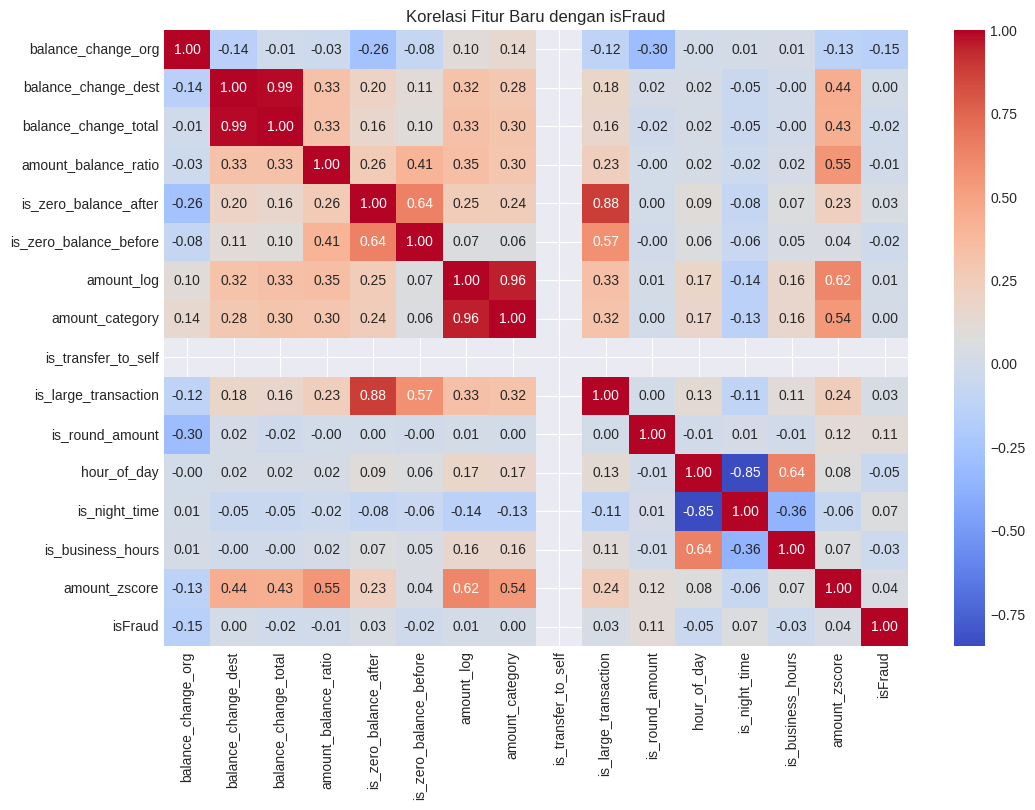

In [ ]:
num_cols = data_fe.select_dtypes(include=np.number).columns
corr_matrix = data_fe[num_cols].corr()

corr_target = corr_matrix['isFraud'].sort_values(ascending=False)

new_corr = corr_target[[c for c in new_cols if c in corr_target.index]]

print("\nTop 15 fitur baru:")
print(new_corr.head(15))

# Heatmap
plt.figure(figsize=(12,8))
sns.heatmap(data_fe[new_corr.head(15).index.tolist() + ['isFraud']].corr(),
            cmap="coolwarm", annot=True, fmt=".2f")
plt.title("Korelasi Fitur Baru dengan isFraud")
plt.show()

In [ ]:
selected = new_corr[ (new_corr > 0.02) | (new_corr < -0.02) ]
print("Jumlah fitur terpilih:", len(selected))
print(selected)

Jumlah fitur terpilih: 10
balance_change_org       -0.150650
is_zero_balance_after     0.034131
is_zero_balance_before   -0.021839
is_large_transaction      0.029957
is_round_amount           0.108965
hour_of_day              -0.051344
is_night_time             0.065892
is_business_hours        -0.028469
amount_zscore             0.041582
is_high_amount            0.022611
Name: isFraud, dtype: float64


In [ ]:
if 'nameOrig' in data_fe:
    data_fe.drop(['nameOrig', 'nameDest'], axis=1, inplace=True)

X = data_fe.drop('isFraud', axis=1)
y = data_fe['isFraud']

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nDistribusi target:")
print(y.value_counts(normalize=True) * 100)

X shape: (83561, 37)
y shape: (83561,)

Distribusi target:
isFraud
0.0    99.865966
1.0     0.134034
Name: proportion, dtype: float64


# Pre Processing


In [ ]:
from sklearn.preprocessing import RobustScaler, PowerTransformer
from sklearn.feature_selection import SelectKBest, mutual_info_classif, RFE
from sklearn.decomposition import PCA
import warnings
warnings.filterwarnings('ignore')

In [ ]:
#Handling Imbalance Data
from imblearn.over_sampling import SMOTE, ADASYN
from imblearn.under_sampling import RandomUnderSampler
from imblearn.combine import SMOTEENN

# Split data sebelum resampling
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Sebelum resampling:")
print(f"  Training: Fraud = {y_train.sum():,}, Non-Fraud = {(y_train == 0).sum():,}")
print(f"  Rasio: 1:{int((y_train == 0).sum()/y_train.sum()):,}")

Sebelum resampling:
  Training: Fraud = 90.0, Non-Fraud = 66,758
  Rasio: 1:741


In [ ]:
#Resampling SMOTE
smote = SMOTE(random_state=42, sampling_strategy=0.1)  # 10% fraud
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

# SMOTE + Undersampling
# rus = RandomUnderSampler(random_state=42, sampling_strategy=0.5)
# X_train_combined, y_train_combined = rus.fit_resample(X_train_smote, y_train_smote)


print(f"\nSetelah resampling:")
print(f"  SMOTE: Fraud = {y_train_smote.sum():,}, Non-Fraud = {(y_train_smote == 0).sum():,}")
print(f"  Rasio: 1:{int((y_train_smote == 0).sum()/y_train_smote.sum()):,}")


Setelah resampling:
  SMOTE: Fraud = 6,675.0, Non-Fraud = 66,758
  Rasio: 1:10


In [ ]:
# Feature Scaling
scaler = RobustScaler()  # Lebih robust terhadap outliers

X_train_scaled = scaler.fit_transform(X_train_smote)
X_test_scaled = scaler.transform(X_test)

In [ ]:
# Feature Selection
# Mutual Information (non-linear relationships)
print("1. Mutual Information Feature Selection:")
mi_selector = SelectKBest(score_func=mutual_info_classif, k=15)
X_train_mi = mi_selector.fit_transform(X_train_scaled, y_train_smote)
selected_features_mi = X.columns[mi_selector.get_support()]
print(f"  Fitur terpilih: {len(selected_features_mi)}")
print(f"  Top 5 fitur: {selected_features_mi[:5].tolist()}")

# PCA untuk dimensionality reduction
print("\n2. Principal Component Analysis (PCA):")
pca = PCA(n_components=0.95)
X_train_pca = pca.fit_transform(X_train_scaled)
print(f"  Komponen awal: {X_train_scaled.shape[1]}")
print(f"  Komponen setelah PCA: {X_train_pca.shape[1]}")
print(f"  Variance explained: {sum(pca.explained_variance_ratio_):.3f}")

1. Mutual Information Feature Selection:
  Fitur terpilih: 15
  Top 5 fitur: ['step', 'type', 'amount', 'oldbalanceOrg', 'balance_change_org']

2. Principal Component Analysis (PCA):
  Komponen awal: 37
  Komponen setelah PCA: 2
  Variance explained: 1.000


# Skenario 1: Baseline

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                           roc_auc_score, precision_recall_curve,
                           average_precision_score, f1_score,
                           accuracy_score, recall_score, precision_score)
import warnings
warnings.filterwarnings('ignore')

In [ ]:
# 1. Data Preparation
features_simple = [
    # Fitur original
    'type', 'amount', 'oldbalanceOrg', 'newbalanceOrig',
    'oldbalanceDest', 'newbalanceDest', 'step',

    # Fitur turunan sederhana (sesuai deskripsi)
    'balance_change_org',       # newbalanceOrig - oldbalanceOrg
    'balance_change_dest',      # newbalanceDest - oldbalanceDest
    'amount_balance_ratio',     # amount / (oldbalanceOrg + 1)

    # Fitur tambahan yang relevan untuk baseline
    'is_zero_balance_after',    # flag untuk saldo nol setelah transaksi
    'is_zero_balance_before',   # flag untuk saldo nol sebelum transaksi
]

available_features = [f for f in features_simple if f in data_fe.columns]
print(f"Fitur yang digunakan: {len(available_features)} fitur")
for i, feat in enumerate(available_features, 1):
    print(f"  {i:2d}. {feat}")

Fitur yang digunakan: 12 fitur
   1. type
   2. amount
   3. oldbalanceOrg
   4. newbalanceOrig
   5. oldbalanceDest
   6. newbalanceDest
   7. step
   8. balance_change_org
   9. balance_change_dest
  10. amount_balance_ratio
  11. is_zero_balance_after
  12. is_zero_balance_before


In [ ]:
# X dan y untuk skenario 1
X_scenario1 = data_fe[available_features]
y_scenario1 = data_fe['isFraud']

print(f"\nShape data untuk Skenario 1:")
print(f"  X: {X_scenario1.shape}")
print(f"  y: {y_scenario1.shape}")

print(f"\nDistribusi kelas TARGET (isFraud):")
fraud_count = (y_scenario1 == 1).sum()
non_fraud_count = (y_scenario1 == 0).sum()
total_count = len(y_scenario1)
fraud_percentage = fraud_count / total_count * 100

print(f"  Non-Fraud (0): {non_fraud_count:,} ({100-fraud_percentage:.3f}%)")
print(f"  Fraud (1):     {fraud_count:,} ({fraud_percentage:.3f}%)")
print(f"  Rasio: 1:{int(non_fraud_count/fraud_count):,}")


Shape data untuk Skenario 1:
  X: (83561, 12)
  y: (83561,)

Distribusi kelas TARGET (isFraud):
  Non-Fraud (0): 83,449 (99.866%)
  Fraud (1):     112 (0.134%)
  Rasio: 1:745


In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X_scenario1, y_scenario1,
    test_size=0.2,
    random_state=42,
    stratify=y_scenario1
)

print(f"Training set: {X_train.shape[0]:,} samples ({X_train.shape[0]/len(X_scenario1)*100:.1f}%)")
print(f"Test set:     {X_test.shape[0]:,} samples ({X_test.shape[0]/len(X_scenario1)*100:.1f}%)")

train_fraud = (y_train == 1).sum()
train_non_fraud = (y_train == 0).sum()
print(f"  Non-Fraud: {train_non_fraud:,} ({(train_non_fraud/len(y_train))*100:.3f}%)")
print(f"  Fraud:     {train_fraud:,} ({(train_fraud/len(y_train))*100:.3f}%)")
print(f"  Rasio: 1:{int(train_non_fraud/train_fraud):,}")

print(f"\nDistribusi kelas di Test set:")
test_fraud = (y_test == 1).sum()
test_non_fraud = (y_test == 0).sum()
print(f"  Non-Fraud: {test_non_fraud:,} ({(test_non_fraud/len(y_test))*100:.3f}%)")
print(f"  Fraud:     {test_fraud:,} ({(test_fraud/len(y_test))*100:.3f}%)")
print(f"  Rasio: 1:{int(test_non_fraud/test_fraud):,}")

Training set: 66,848 samples (80.0%)
Test set:     16,713 samples (20.0%)
  Non-Fraud: 66,758 (99.865%)
  Fraud:     90 (0.135%)
  Rasio: 1:741

Distribusi kelas di Test set:
  Non-Fraud: 16,691 (99.868%)
  Fraud:     22 (0.132%)
  Rasio: 1:758


In [ ]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"  Training shape setelah scaling: {X_train_scaled.shape}")
print(f"  Test shape setelah scaling: {X_test_scaled.shape}")

  Training shape setelah scaling: (66848, 12)
  Test shape setelah scaling: (16713, 12)


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                           roc_auc_score, precision_recall_curve,
                           average_precision_score, f1_score,
                           accuracy_score, recall_score, precision_score,
                           roc_curve, matthews_corrcoef, balanced_accuracy_score)
import time
import warnings
warnings.filterwarnings('ignore')

models = {
    # Single Learning sesuai batasan masalah
    'Logistic Regression': LogisticRegression(
        class_weight='balanced',
        random_state=42,
        max_iter=1000
    ),

    'Decision Tree': DecisionTreeClassifier(
        class_weight='balanced',
        random_state=42,
        max_depth=10  # Akan di-tuning
    )
}

print("Model yang akan dievaluasi di Skenario 1:")
print("-" * 40)
for i, (model_name, model) in enumerate(models.items(), 1):
    print(f"  {i}. {model_name}")
    print(f"     Parameters: {model.get_params()}")


Model yang akan dievaluasi di Skenario 1:
----------------------------------------
  1. Logistic Regression
     Parameters: {'C': 1.0, 'class_weight': 'balanced', 'dual': False, 'fit_intercept': True, 'intercept_scaling': 1, 'l1_ratio': None, 'max_iter': 1000, 'multi_class': 'deprecated', 'n_jobs': None, 'penalty': 'l2', 'random_state': 42, 'solver': 'lbfgs', 'tol': 0.0001, 'verbose': 0, 'warm_start': False}
  2. Decision Tree
     Parameters: {'ccp_alpha': 0.0, 'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': 10, 'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'random_state': 42, 'splitter': 'best'}


In [ ]:
param_grids = {
    'Logistic Regression': {
        'C': [0.01, 0.1, 1, 10, 100],  # Regularization strength
        'solver': ['liblinear', 'lbfgs']
    },
    'Decision Tree': {
        'max_depth': [5, 10, 15, 20, None],  # Maximum depth
        'min_samples_split': [2, 5, 10],  # Minimum samples to split
        'min_samples_leaf': [1, 2, 4]  # Minimum samples at leaf
    }
}

# Dictionary untuk menyimpan hasil
best_models = {}
cv_results = {}
training_times = {}

print("\nHyperparameter Tuning dengan 5-fold CV:")
print("-" * 50)

for model_name, model in models.items():
    print(f"\nTuning {model_name}...")
    start_time = time.time()

    grid_search = GridSearchCV(
        estimator=model,
        param_grid=param_grids[model_name],
        cv=5,  # 5-fold cross validation
        scoring='roc_auc',  # Gunakan ROC-AUC untuk imbalance data
        n_jobs=-1,
        verbose=0
    )

    # Training dengan cross-validation
    grid_search.fit(X_train_scaled, y_train)
    training_time = time.time() - start_time

    # Simpan model terbaik
    best_models[model_name] = grid_search.best_estimator_
    cv_results[model_name] = {
        'best_score': grid_search.best_score_,
        'best_params': grid_search.best_params_,
        'cv_scores': grid_search.cv_results_['mean_test_score']
    }
    training_times[model_name] = training_time

    print(f"  Training time: {training_time:.1f} seconds")
    print(f"  Best ROC-AUC: {grid_search.best_score_:.4f}")
    print(f"  Best parameters: {grid_search.best_params_}")


Hyperparameter Tuning dengan 5-fold CV:
--------------------------------------------------

Tuning Logistic Regression...
  Training time: 16.1 seconds
  Best ROC-AUC: 0.9721
  Best parameters: {'C': 1, 'solver': 'liblinear'}

Tuning Decision Tree...
  Training time: 48.8 seconds
  Best ROC-AUC: 0.9444
  Best parameters: {'max_depth': 15, 'min_samples_leaf': 2, 'min_samples_split': 10}


In [ ]:
results = {}
detailed_results = {}
test_times = {}

for model_name, model in best_models.items():
    print(f"\n{'='*60}")
    print(f"EVALUASI MODEL: {model_name}")
    print(f"{'='*60}")

    # Predictions with timing
    start_time = time.time()
    y_pred = model.predict(X_test_scaled)
    y_pred_proba = model.predict_proba(X_test_scaled)[:, 1]
    test_time = time.time() - start_time
    test_times[model_name] = test_time

    # Confusion Matrix
    cm = confusion_matrix(y_test, y_pred)
    tn, fp, fn, tp = cm.ravel()

    # Calculate metrics lengkap
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred) if (tp + fp) > 0 else 0
    recall = recall_score(y_test, y_pred) if (tp + fn) > 0 else 0
    f1 = f1_score(y_test, y_pred) if (precision + recall) > 0 else 0
    roc_auc = roc_auc_score(y_test, y_pred_proba)
    pr_auc = average_precision_score(y_test, y_pred_proba)

    # False Negative Rate (FNR) - sangat penting untuk fraud detection
    fnr = fn / (fn + tp) if (fn + tp) > 0 else 0

    # False Positive Rate (FPR)
    fpr = fp / (fp + tn) if (fp + tn) > 0 else 0

    # True Negative Rate (TNR/Specificity)
    tnr = tn / (tn + fp) if (tn + fp) > 0 else 0

    # Additional metrics for imbalanced data
    mcc = matthews_corrcoef(y_test, y_pred)
    balanced_acc = balanced_accuracy_score(y_test, y_pred)

    # Save detailed results
    detailed_results[model_name] = {
        'model': model,
        'y_pred': y_pred,
        'y_pred_proba': y_pred_proba,
        'confusion_matrix': cm,
        'tn': tn, 'fp': fp, 'fn': fn, 'tp': tp
    }

    # Save summary results
    results[model_name] = {
        'accuracy': accuracy,
        'precision': precision,
        'recall': recall,
        'f1_score': f1,
        'roc_auc': roc_auc,
        'pr_auc': pr_auc,
        'fnr': fnr,
        'fpr': fpr,
        'tnr': tnr,
        'mcc': mcc,
        'balanced_accuracy': balanced_acc,
        'cv_score': cv_results[model_name]['best_score'],
        'training_time': training_times[model_name],
        'test_time': test_time
    }

    # Display results
    print(f"\nCONFUSION MATRIX:")
    print(f"{'':<20} {'Predicted Negative':<20} {'Predicted Positive':<20}")
    print(f"{'Actual Negative':<20} {tn:<20} {fp:<20}")
    print(f"{'Actual Positive':<20} {fn:<20} {tp:<20}")

    print(f"\nMETRIK UTAMA (fokus pada kelas Fraud):")
    print(f"  Accuracy:          {accuracy:.4f}")
    print(f"  Precision (Fraud): {precision:.4f}")
    print(f"  Recall (Fraud):    {recall:.4f}")
    print(f"  F1-Score:          {f1:.4f}")

    print(f"\nMETRIK TAMBAHAN:")
    print(f"  ROC-AUC:           {roc_auc:.4f}")
    print(f"  PR-AUC:            {pr_auc:.4f}")
    print(f"  False Negative Rate: {fnr:.4f}")
    print(f"  False Positive Rate: {fpr:.4f}")
    print(f"  MCC:               {mcc:.4f}")
    print(f"  Balanced Accuracy: {balanced_acc:.4f}")

    print(f"\nPERFORMANCE:")
    print(f"  Training time:     {training_times[model_name]:.1f}s")
    print(f"  Test time:         {test_time:.4f}s")
    print(f"  CV ROC-AUC:        {cv_results[model_name]['best_score']:.4f}")

    # Classification report
    print(f"\nCLASSIFICATION REPORT:")
    print(classification_report(y_test, y_pred, target_names=['Non-Fraud', 'Fraud'], digits=4))



EVALUASI MODEL: Logistic Regression

CONFUSION MATRIX:
                     Predicted Negative   Predicted Positive  
Actual Negative      15304                1387                
Actual Positive      0                    22                  

METRIK UTAMA (fokus pada kelas Fraud):
  Accuracy:          0.9170
  Precision (Fraud): 0.0156
  Recall (Fraud):    1.0000
  F1-Score:          0.0307

METRIK TAMBAHAN:
  ROC-AUC:           0.9914
  PR-AUC:            0.3123
  False Negative Rate: 0.0000
  False Positive Rate: 0.0831
  MCC:               0.1197
  Balanced Accuracy: 0.9585

PERFORMANCE:
  Training time:     16.1s
  Test time:         0.0038s
  CV ROC-AUC:        0.9721

CLASSIFICATION REPORT:
              precision    recall  f1-score   support

   Non-Fraud     1.0000    0.9169    0.9566     16691
       Fraud     0.0156    1.0000    0.0307        22

    accuracy                         0.9170     16713
   macro avg     0.5078    0.9585    0.4937     16713
weighted avg     0.

In [ ]:
# Create comparison dataframe
comparison_df = pd.DataFrame(results).T

# Reorder columns for better readability
column_order = [
    'accuracy', 'balanced_accuracy', 'precision', 'recall', 'f1_score',
    'roc_auc', 'pr_auc', 'mcc', 'fnr', 'fpr', 'tnr',
    'cv_score', 'training_time', 'test_time'
]

comparison_df = comparison_df[column_order]

print("\nTABEL PERBANDINGAN MODEL:")
print(comparison_df.sort_values('recall', ascending=False).to_string(float_format=lambda x: f"{x:.4f}" if x < 10 else f"{x:.1f}"))



TABEL PERBANDINGAN MODEL:
                     accuracy  balanced_accuracy  precision  recall  f1_score  roc_auc  pr_auc    mcc    fnr    fpr    tnr  cv_score  training_time  test_time
Logistic Regression    0.9170             0.9585     0.0156  1.0000    0.0307   0.9914  0.3123 0.1197 0.0000 0.0831 0.9169    0.9721           16.1     0.0038
Decision Tree          0.9993             0.9542     0.6667  0.9091    0.7692   0.9545  0.8618 0.7782 0.0909 0.0006 0.9994    0.9444           48.8     0.0028



Visualisasi Confusion Matrices...
Visualisasi ROC Curves...
Visualisasi Precision-Recall Curves...
Visualisasi perbandingan metrik utama...


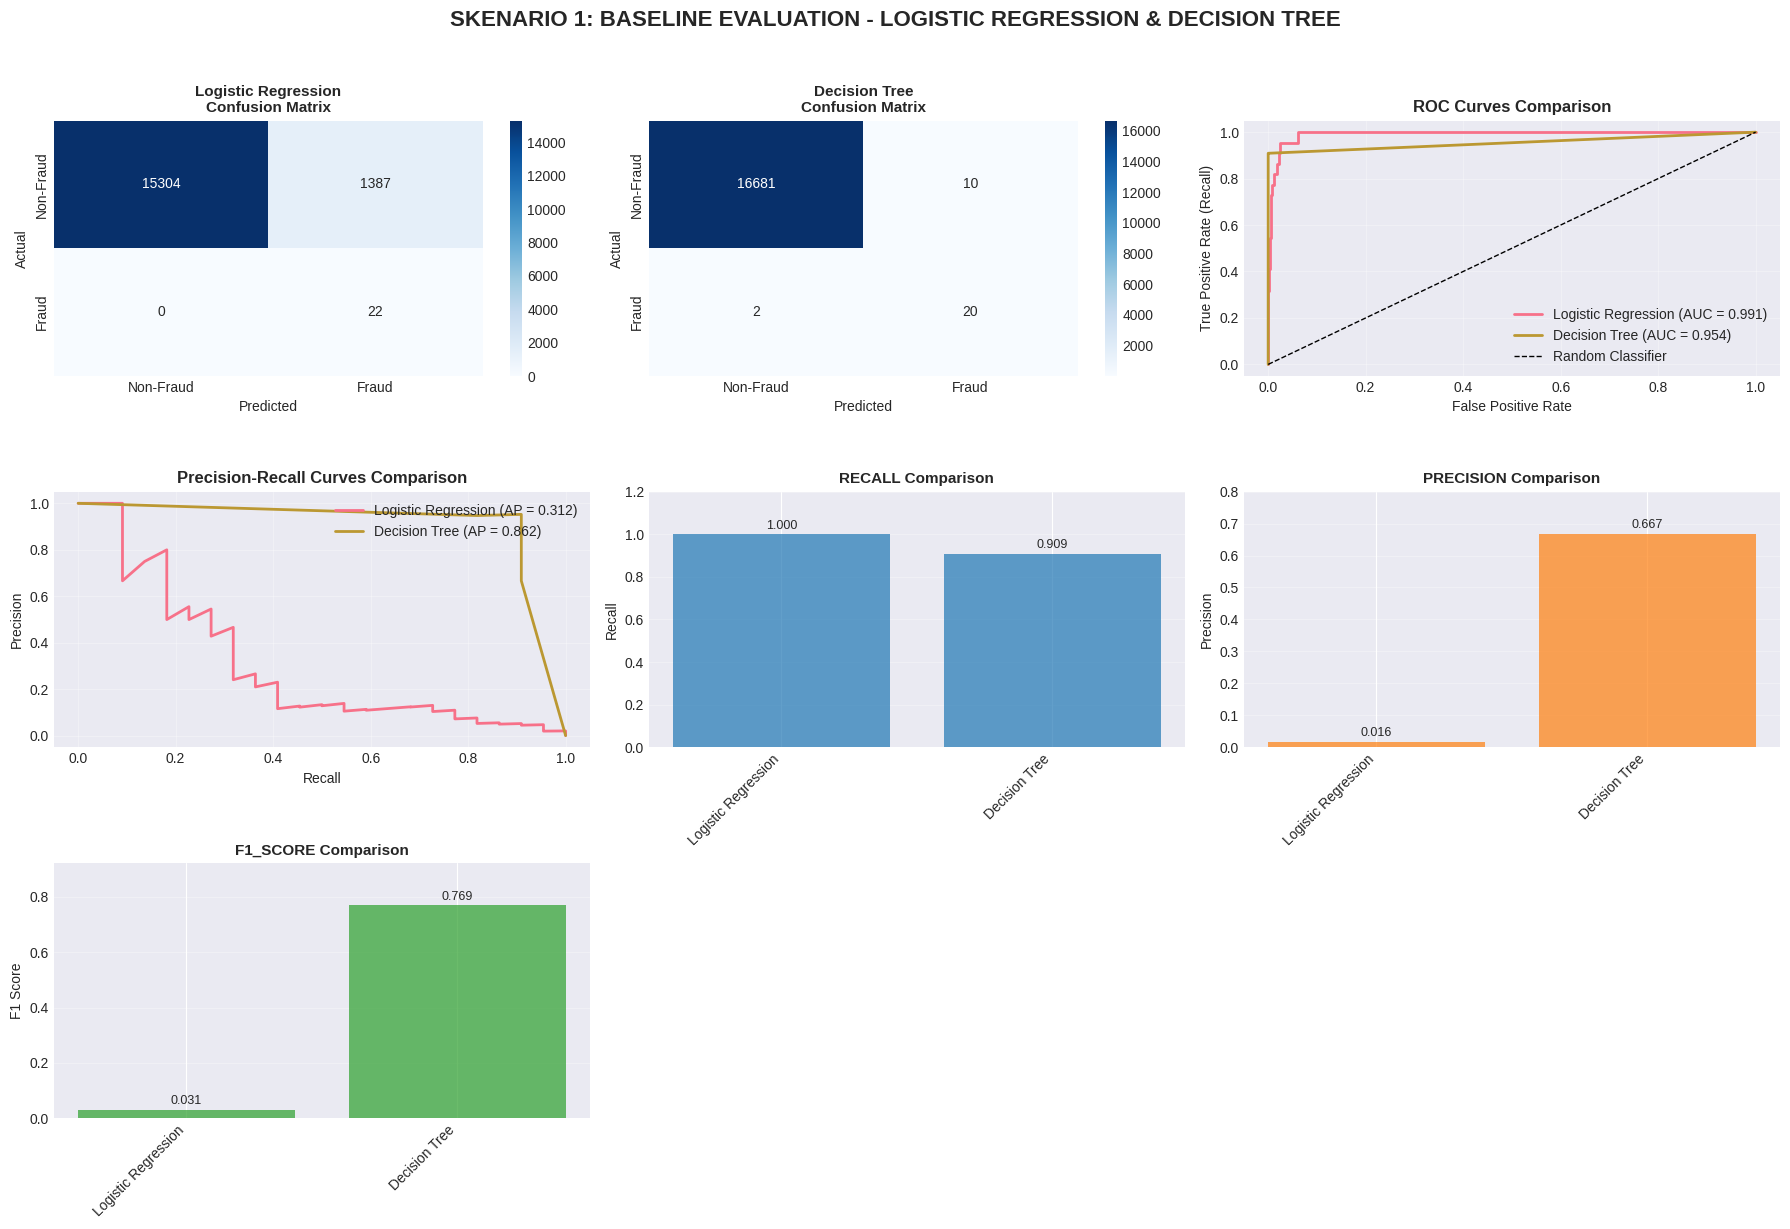

In [ ]:
# Create visualizations
fig = plt.figure(figsize=(18, 12))
fig.suptitle('SKENARIO 1: BASELINE EVALUATION - LOGISTIC REGRESSION & DECISION TREE',
             fontsize=16, fontweight='bold', y=1.02)

# 1. Confusion Matrices
print("\nVisualisasi Confusion Matrices...")
model_names = list(best_models.keys())
for idx, model_name in enumerate(model_names, 1):
    plt.subplot(3, 3, idx)
    cm = detailed_results[model_name]['confusion_matrix']
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Non-Fraud', 'Fraud'],
                yticklabels=['Non-Fraud', 'Fraud'])
    plt.title(f'{model_name}\nConfusion Matrix', fontweight='bold', fontsize=11)
    plt.ylabel('Actual', fontsize=10)
    plt.xlabel('Predicted', fontsize=10)

# 2. ROC Curves
print("Visualisasi ROC Curves...")
plt.subplot(3, 3, 3)
for model_name in results.keys():
    y_pred_proba = detailed_results[model_name]['y_pred_proba']
    fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
    plt.plot(fpr, tpr, label=f'{model_name} (AUC = {results[model_name]["roc_auc"]:.3f})', linewidth=2)

plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier', linewidth=1)
plt.xlabel('False Positive Rate', fontsize=10)
plt.ylabel('True Positive Rate (Recall)', fontsize=10)
plt.title('ROC Curves Comparison', fontweight='bold', fontsize=12)
plt.legend(loc='lower right', fontsize=10)
plt.grid(alpha=0.3)

# 3. Precision-Recall Curves
print("Visualisasi Precision-Recall Curves...")
plt.subplot(3, 3, 4)
for model_name in results.keys():
    y_pred_proba = detailed_results[model_name]['y_pred_proba']
    precision_curve, recall_curve, _ = precision_recall_curve(y_test, y_pred_proba)
    pr_auc = results[model_name]['pr_auc']
    plt.plot(recall_curve, precision_curve,
             label=f'{model_name} (AP = {pr_auc:.3f})',
             linewidth=2)

plt.xlabel('Recall', fontsize=10)
plt.ylabel('Precision', fontsize=10)
plt.title('Precision-Recall Curves Comparison', fontweight='bold', fontsize=12)
plt.legend(loc='upper right', fontsize=10)
plt.grid(alpha=0.3)

# 4. Bar chart for key metrics
print("Visualisasi perbandingan metrik utama...")
metrics_to_plot = ['recall', 'precision', 'f1_score']
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']

for idx, metric in enumerate(metrics_to_plot, 1):
    plt.subplot(3, 3, 4 + idx)
    values = [results[m][metric] for m in results.keys()]
    bars = plt.bar(results.keys(), values, color=colors[idx-1], alpha=0.7)
    plt.title(f'{metric.upper()} Comparison', fontweight='bold', fontsize=11)
    plt.ylabel(metric.replace('_', ' ').title(), fontsize=10)
    plt.xticks(rotation=45, ha='right', fontsize=10)
    plt.ylim(0, max(values) * 1.2)
    plt.grid(axis='y', alpha=0.3)

    # Add value labels on bars
    for bar, value in zip(bars, values):
        plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                f'{value:.3f}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()


Radar Chart untuk Perbandingan Model...


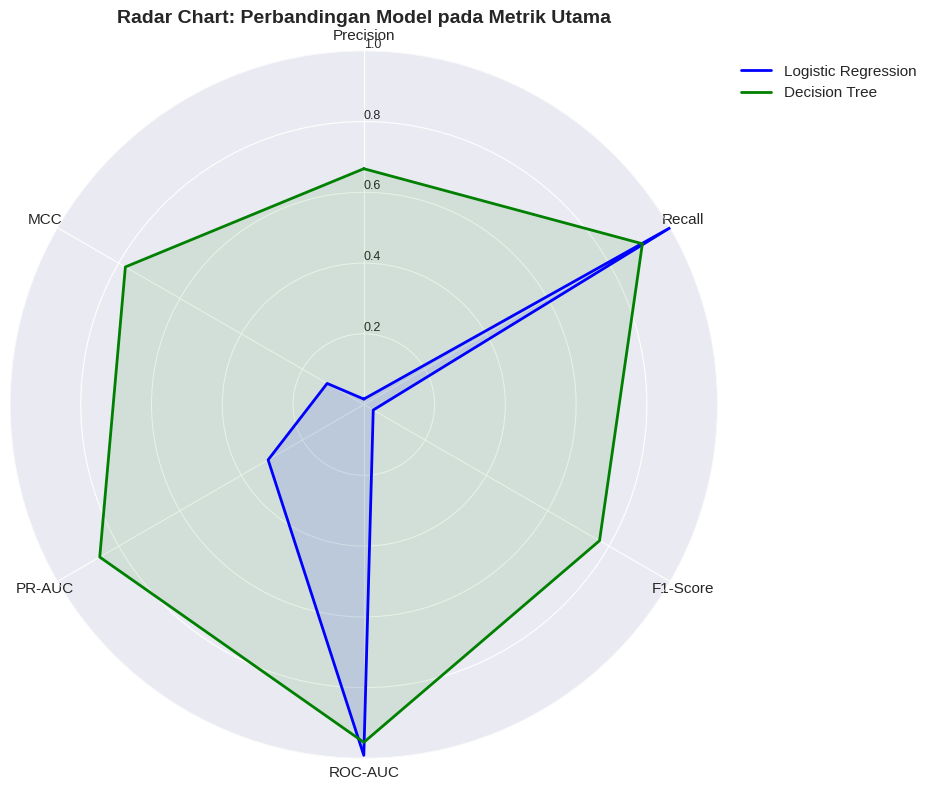

In [ ]:
# Radar chart for model comparison
print("\nRadar Chart untuk Perbandingan Model...")
fig = plt.figure(figsize=(10, 8))

# Metrics to include in radar chart
radar_metrics = ['precision', 'recall', 'f1_score', 'roc_auc', 'pr_auc', 'mcc']
radar_labels = ['Precision', 'Recall', 'F1-Score', 'ROC-AUC', 'PR-AUC', 'MCC']

# Number of variables
num_vars = len(radar_metrics)

# Compute angle for each axis
angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()
angles += angles[:1]  # Close the loop

# Initialize radar chart
ax = plt.subplot(111, polar=True)
ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)

# Draw one axe per variable and add labels
plt.xticks(angles[:-1], radar_labels, fontsize=11)

# Draw ylabels
ax.set_rlabel_position(0)
plt.yticks([0.2, 0.4, 0.6, 0.8, 1.0], ["0.2", "0.4", "0.6", "0.8", "1.0"], fontsize=9)
plt.ylim(0, 1)

# Plot each model
colors = ['blue', 'green']
for idx, (model_name, color) in enumerate(zip(results.keys(), colors)):
    values = [results[model_name][metric] for metric in radar_metrics]
    values += values[:1]  # Close the loop

    ax.plot(angles, values, color=color, linewidth=2, label=model_name)
    ax.fill(angles, values, color=color, alpha=0.1)

plt.title('Radar Chart: Perbandingan Model pada Metrik Utama',
          fontsize=14, fontweight='bold', pad=20)
plt.legend(loc='upper right', bbox_to_anchor=(1.3, 1.0), fontsize=11)
plt.tight_layout()
plt.show()

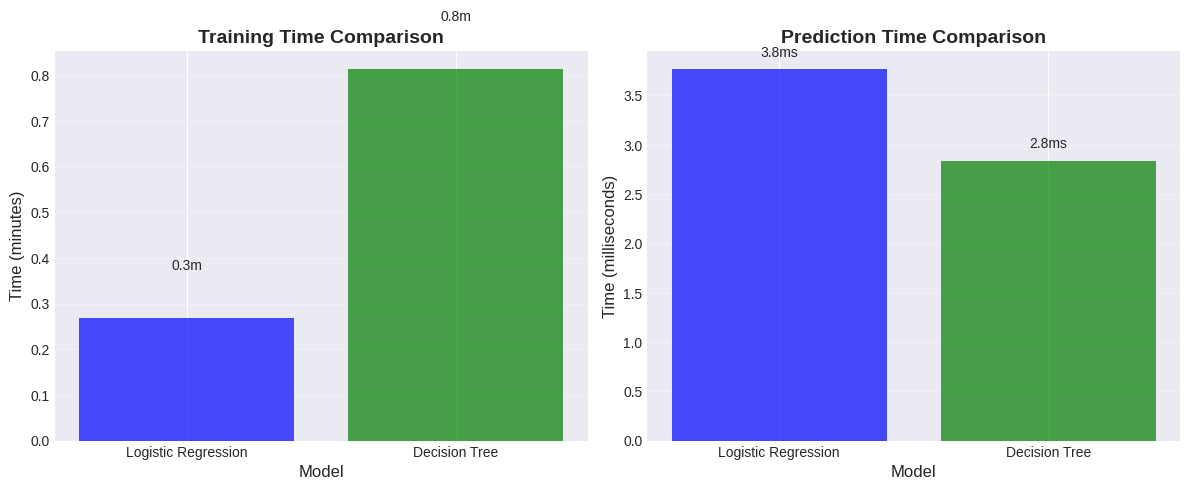

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Training time comparison
times_seconds = [results[m]['training_time'] for m in results.keys()]
times_minutes = [t/60 for t in times_seconds]

bars1 = axes[0].bar(results.keys(), times_minutes, color=['blue', 'green'], alpha=0.7)
axes[0].set_title('Training Time Comparison', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Time (minutes)', fontsize=12)
axes[0].set_xlabel('Model', fontsize=12)
axes[0].grid(axis='y', alpha=0.3)

for bar, minutes in zip(bars1, times_minutes):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.1,
                f'{minutes:.1f}m', ha='center', va='bottom', fontsize=10)

# Test time comparison
test_times_ms = [results[m]['test_time'] * 1000 for m in results.keys()]  # Convert to milliseconds

bars2 = axes[1].bar(results.keys(), test_times_ms, color=['blue', 'green'], alpha=0.7)
axes[1].set_title('Prediction Time Comparison', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Time (milliseconds)', fontsize=12)
axes[1].set_xlabel('Model', fontsize=12)
axes[1].grid(axis='y', alpha=0.3)

for bar, ms in zip(bars2, test_times_ms):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.1,
                f'{ms:.1f}ms', ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

In [ ]:
print("\nB. HASIL AKTUAL:")
# Find best model for each metric
best_f1 = comparison_df['f1_score'].idxmax()
best_recall = comparison_df['recall'].idxmax()
best_precision = comparison_df['precision'].idxmax()
best_roc_auc = comparison_df['roc_auc'].idxmax()
best_mcc = comparison_df['mcc'].idxmax()

print(f"   - Model dengan F1 tertinggi: {best_f1} ({comparison_df.loc[best_f1, 'f1_score']:.4f})")
print(f"   - Model dengan Recall tertinggi: {best_recall} ({comparison_df.loc[best_recall, 'recall']:.4f})")
print(f"   - Model dengan Precision tertinggi: {best_precision} ({comparison_df.loc[best_precision, 'precision']:.4f})")
print(f"   - Model dengan ROC-AUC tertinggi: {best_roc_auc} ({comparison_df.loc[best_roc_auc, 'roc_auc']:.4f})")
print(f"   - Model dengan MCC tertinggi: {best_mcc} ({comparison_df.loc[best_mcc, 'mcc']:.4f})")

print("\nC. ANALISIS FALSE NEGATIVE RATE (FNR):")
print("   (Semakin rendah FNR, semakin baik untuk fraud detection)")
for model_name in results.keys():
    fnr = results[model_name]['fnr']
    print(f"   - {model_name}: {fnr:.4f} → {fnr*100:.1f}% fraud tidak terdeteksi")

print("\nD. TRADE-OFF PRECISION-RECALL:")
print("   (Dalam fraud detection, Recall biasanya lebih penting daripada Precision)")
for model_name in results.keys():
    precision = results[model_name]['precision']
    recall = results[model_name]['recall']
    f1 = results[model_name]['f1_score']
    print(f"   - {model_name}: Precision={precision:.3f}, Recall={recall:.3f}, F1={f1:.3f}")

print("\nE. REKOMENDASI UNTUK SKENARIO BERIKUTNYA:")
print("   1. Gunakan teknik resampling (SMOTE, ADASYN) untuk handle class imbalance")
print("   2. Implementasi ensemble methods (Random Forest, XGBoost, LightGBM)")
print("   3. Cost-sensitive learning dengan bobot berbeda untuk FP dan FN")
print("   4. Threshold optimization berdasarkan business cost matrix")
print("   5. Feature engineering lebih mendalam dengan domain knowledge")

print("\nF. MODEL TERBAIK UNTUK BASELINE:")
best_overall = max(results.items(), key=lambda x: 0.4*x[1]['f1_score'] + 0.3*x[1]['recall'] + 0.2*x[1]['precision'] + 0.1*x[1]['roc_auc'])
print(f"   - Model: {best_overall[0]}")
print(f"   - F1-Score: {best_overall[1]['f1_score']:.4f}")
print(f"   - Recall: {best_overall[1]['recall']:.4f}")
print(f"   - Precision: {best_overall[1]['precision']:.4f}")
print(f"   - ROC-AUC: {best_overall[1]['roc_auc']:.4f}")
print(f"   - FNR: {best_overall[1]['fnr']:.4f} ({best_overall[1]['fnr']*100:.1f}% fraud tidak terdeteksi)")


B. HASIL AKTUAL:
   - Model dengan F1 tertinggi: Decision Tree (0.7692)
   - Model dengan Recall tertinggi: Logistic Regression (1.0000)
   - Model dengan Precision tertinggi: Decision Tree (0.6667)
   - Model dengan ROC-AUC tertinggi: Logistic Regression (0.9914)
   - Model dengan MCC tertinggi: Decision Tree (0.7782)

C. ANALISIS FALSE NEGATIVE RATE (FNR):
   (Semakin rendah FNR, semakin baik untuk fraud detection)
   - Logistic Regression: 0.0000 → 0.0% fraud tidak terdeteksi
   - Decision Tree: 0.0909 → 9.1% fraud tidak terdeteksi

D. TRADE-OFF PRECISION-RECALL:
   (Dalam fraud detection, Recall biasanya lebih penting daripada Precision)
   - Logistic Regression: Precision=0.016, Recall=1.000, F1=0.031
   - Decision Tree: Precision=0.667, Recall=0.909, F1=0.769

E. REKOMENDASI UNTUK SKENARIO BERIKUTNYA:
   1. Gunakan teknik resampling (SMOTE, ADASYN) untuk handle class imbalance
   2. Implementasi ensemble methods (Random Forest, XGBoost, LightGBM)
   3. Cost-sensitive learning de

In [ ]:
# Save results for scenario 2
scenario1_results = {
    'X_train': X_train_scaled,
    'X_test': X_test_scaled,
    'y_train': y_train,
    'y_test': y_test,
    'best_models': best_models,
    'results': results,
    'comparison_df': comparison_df,
    'scaler': scaler,
    'feature_names': available_features,
    'param_grids': param_grids,
    'cv_results': cv_results,
    'training_times': training_times,
    'detailed_results': detailed_results
}

# Save to pickle
import pickle
with open('scenario1_results_logreg_dt.pkl', 'wb') as f:
    pickle.dump(scenario1_results, f)

# Save comparison table to CSV
comparison_df.to_csv('scenario1_comparison_logreg_dt.csv')

print("✓ Hasil disimpan dalam file:")
print("  - scenario1_results_logreg_dt.pkl")
print("  - scenario1_comparison_logreg_dt.csv")

✓ Hasil disimpan dalam file:
  - scenario1_results_logreg_dt.pkl
  - scenario1_comparison_logreg_dt.csv


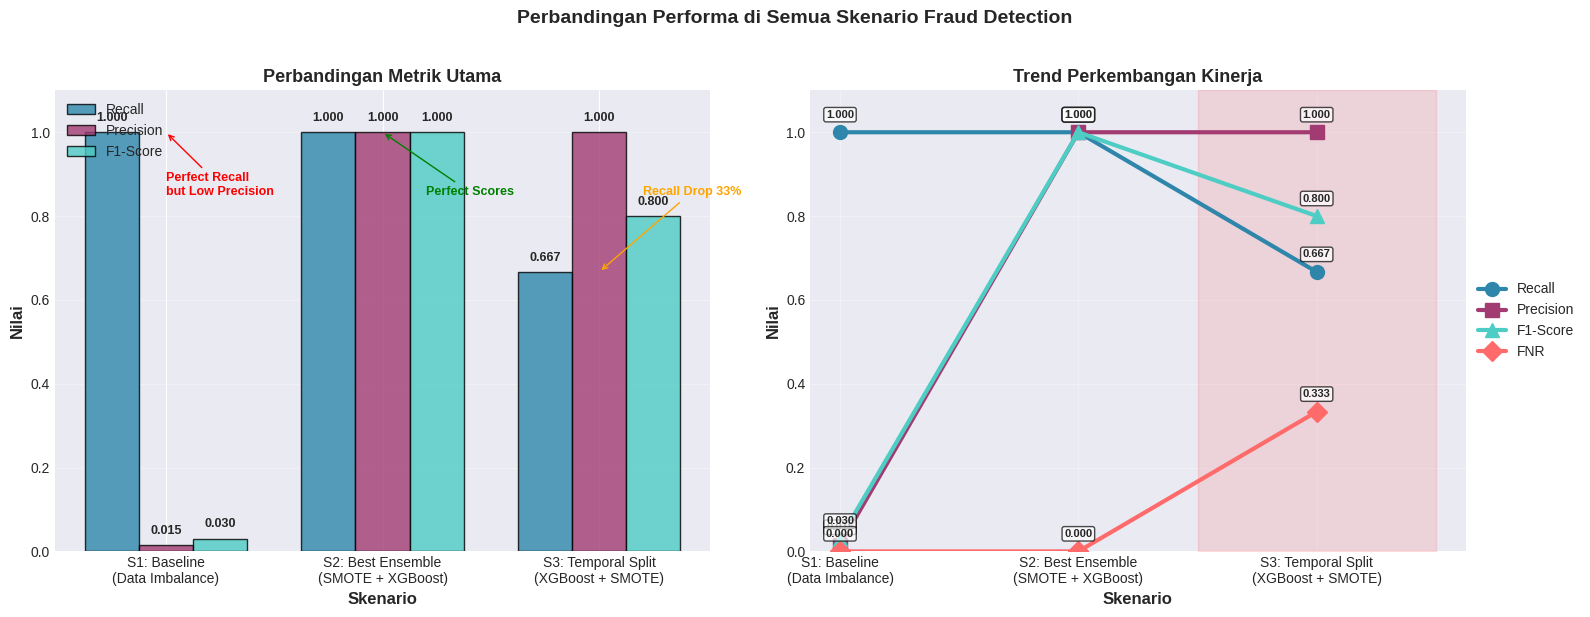

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Set style
plt.style.use('seaborn-v0_8-darkgrid')

# Data dari hasil eksperimen
scenarios_data = {
    'Scenario': ['S1: Baseline\n(Data Imbalance)', 'S2: Best Ensemble\n(SMOTE + XGBoost)', 'S3: Temporal Split\n(XGBoost + SMOTE)'],
    'Recall': [1.0000, 1.0000, 0.6667],
    'Precision': [0.0155, 1.0000, 1.0000],
    'F1-Score': [0.0304, 1.0000, 0.8000],
    'FNR': [0.0000, 0.0000, 0.3333]
}

scenarios_df = pd.DataFrame(scenarios_data)

# ============================================================
# VISUALISASI 1: GROUPED BAR CHART - Semua Metrik
# ============================================================
fig1, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
fig1.suptitle('Perbandingan Performa di Semua Skenario Fraud Detection',
              fontsize=14, fontweight='bold', y=1.02)

# Subplot 1: Grouped Bar Chart untuk Recall, Precision, F1-Score
x = np.arange(len(scenarios_df['Scenario']))
width = 0.25

bars1 = ax1.bar(x - width, scenarios_df['Recall'], width,
                label='Recall', color='#2E86AB', alpha=0.8, edgecolor='black')
bars2 = ax1.bar(x, scenarios_df['Precision'], width,
                label='Precision', color='#A23B72', alpha=0.8, edgecolor='black')
bars3 = ax1.bar(x + width, scenarios_df['F1-Score'], width,
                label='F1-Score', color='#4ECDC4', alpha=0.8, edgecolor='black')

ax1.set_xlabel('Skenario', fontsize=12, fontweight='bold')
ax1.set_ylabel('Nilai', fontsize=12, fontweight='bold')
ax1.set_title('Perbandingan Metrik Utama', fontsize=13, fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels(scenarios_df['Scenario'], fontsize=10)
ax1.legend(loc='upper left', fontsize=10)
ax1.grid(True, alpha=0.3, axis='y')
ax1.set_ylim([0, 1.1])

# Tambah nilai di atas bar
for bars in [bars1, bars2, bars3]:
    for bar in bars:
        height = bar.get_height()
        ax1.text(bar.get_x() + bar.get_width()/2., height + 0.02,
                f'{height:.3f}', ha='center', va='bottom',
                fontsize=9, fontweight='bold')

# Highlight performa terbaik
ax1.annotate('Perfect Recall\nbut Low Precision',
             xy=(0, 1.0), xytext=(0, 0.85),
             arrowprops=dict(arrowstyle='->', color='red'),
             fontsize=9, color='red', fontweight='bold')

ax1.annotate('Perfect Scores',
             xy=(1, 1.0), xytext=(1.2, 0.85),
             arrowprops=dict(arrowstyle='->', color='green'),
             fontsize=9, color='green', fontweight='bold')

ax1.annotate('Recall Drop 33%',
             xy=(2, 0.6667), xytext=(2.2, 0.85),
             arrowprops=dict(arrowstyle='->', color='orange'),
             fontsize=9, color='orange', fontweight='bold')

# Subplot 2: Line Chart untuk Trend Perkembangan
ax2.plot(scenarios_df['Scenario'], scenarios_df['Recall'],
         'o-', linewidth=3, markersize=10, label='Recall', color='#2E86AB')
ax2.plot(scenarios_df['Scenario'], scenarios_df['Precision'],
         's-', linewidth=3, markersize=10, label='Precision', color='#A23B72')
ax2.plot(scenarios_df['Scenario'], scenarios_df['F1-Score'],
         '^-', linewidth=3, markersize=10, label='F1-Score', color='#4ECDC4')
ax2.plot(scenarios_df['Scenario'], scenarios_df['FNR'],
         'D-', linewidth=3, markersize=10, label='FNR', color='#FF6B6B')

ax2.set_xlabel('Skenario', fontsize=12, fontweight='bold')
ax2.set_ylabel('Nilai', fontsize=12, fontweight='bold')
ax2.set_title('Trend Perkembangan Kinerja', fontsize=13, fontweight='bold')
ax2.legend(loc='center left', bbox_to_anchor=(1, 0.5), fontsize=10)
ax2.grid(True, alpha=0.3)
ax2.set_ylim([0, 1.1])

# Tambah nilai pada titik
for idx, scenario in enumerate(scenarios_df['Scenario']):
    for metric, color in zip(['Recall', 'Precision', 'F1-Score', 'FNR'],
                            ['#2E86AB', '#A23B72', '#4ECDC4', '#FF6B6B']):
        value = scenarios_df.loc[idx, metric]
        ax2.text(idx, value + 0.03, f'{value:.3f}',
                ha='center', va='bottom', fontsize=8, fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.7))

# Highlight area degradasi
ax2.fill_between([1.5, 2.5], [0, 0], [1.1, 1.1],
                alpha=0.1, color='red', label='Temporal Degradation')

plt.tight_layout()
plt.show()

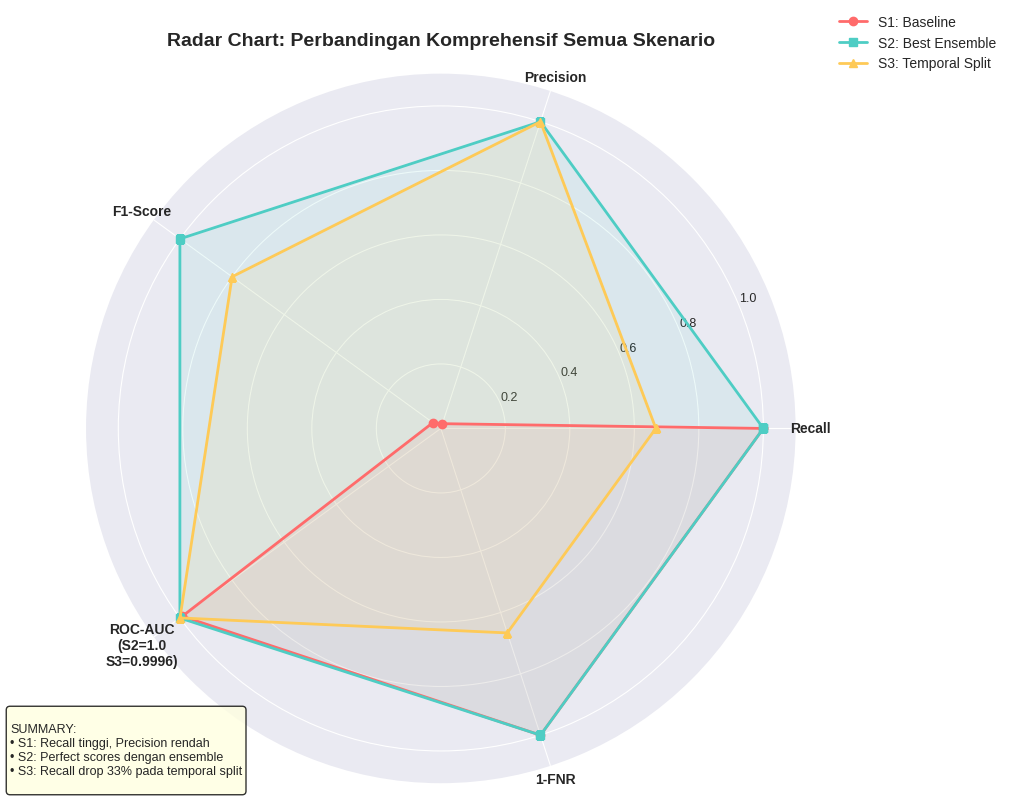


SUMMARY PERBANDINGAN SEMUA SKENARIO

PERFORMANCE OVERVIEW:
----------------------------------------
Scenario                            Recall     Precision  F1-Score   FNR       
----------------------------------------
S1: Baseline
(Data Imbalance)       1.0000     0.0155     0.0304     0.0000    
S2: Best Ensemble
(SMOTE + XGBoost) 1.0000     1.0000     1.0000     0.0000    
S3: Temporal Split
(XGBoost + SMOTE) 0.6667     1.0000     0.8000     0.3333    

KEY INSIGHTS:
1. SKENARIO 1 (Baseline):
   • Recall sempurna (1.0000) tapi Precision sangat rendah (0.0155)
   • Model cenderung over-predict fraud karena imbalance
   • F1-Score rendah (0.0304) menunjukkan performa buruk

2. SKENARIO 2 (Ensemble + SMOTE):
   • Performa sempurna untuk semua metrik
   • Kombinasi XGBoost + SMOTE optimal
   • Ensemble meningkatkan F1-Score 928% dari baseline

3. SKENARIO 3 (Temporal Split):
   • Recall drop signifikan (33.33%)
   • Precision tetap tinggi (1.0000)
   • Indikasi kuat temporal drift
  

In [ ]:
# VISUALISASI 2: RADAR CHART untuk Perbandingan Komprehensif
# ============================================================
fig2, ax = plt.subplots(figsize=(10, 8), subplot_kw=dict(polar=True))

# Data untuk radar chart
metrics = ['Recall', 'Precision', 'F1-Score', 'ROC-AUC\n(S2=1.0\nS3=0.9996)', '1-FNR']
num_vars = len(metrics)

# Nilai untuk setiap skenario
# Untuk S1: ROC-AUC = 0.9907 (Logistic Regression)
# Untuk S2: ROC-AUC = 1.0000
# Untuk S3: ROC-AUC = 0.9996
s1_values = [1.0000, 0.0155, 0.0304, 0.9907, 1.0000]  # 1-FNR = 1 - 0 = 1
s2_values = [1.0000, 1.0000, 1.0000, 1.0000, 1.0000]  # 1-FNR = 1 - 0 = 1
s3_values = [0.6667, 1.0000, 0.8000, 0.9996, 0.6667]  # 1-FNR = 1 - 0.3333 = 0.6667

# Normalize untuk radar chart (skala 0-1 sudah)
angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()

# Tutup polygon
s1_values += s1_values[:1]
s2_values += s2_values[:1]
s3_values += s3_values[:1]
angles += angles[:1]

# Plot
ax.plot(angles, s1_values, 'o-', linewidth=2, label='S1: Baseline', color='#FF6B6B')
ax.fill(angles, s1_values, alpha=0.1, color='#FF6B6B')
ax.plot(angles, s2_values, 's-', linewidth=2, label='S2: Best Ensemble', color='#4ECDC4')
ax.fill(angles, s2_values, alpha=0.1, color='#4ECDC4')
ax.plot(angles, s3_values, '^-', linewidth=2, label='S3: Temporal Split', color='#FECA57')
ax.fill(angles, s3_values, alpha=0.1, color='#FECA57')

# Atur label
ax.set_xticks(angles[:-1])
ax.set_xticklabels(metrics, fontsize=10, fontweight='bold')
ax.set_ylim(0, 1.1)
ax.set_yticks([0.2, 0.4, 0.6, 0.8, 1.0])
ax.set_yticklabels(['0.2', '0.4', '0.6', '0.8', '1.0'], fontsize=9)
ax.grid(True)

# Title dan legend
ax.set_title('Radar Chart: Perbandingan Komprehensif Semua Skenario',
             fontsize=14, fontweight='bold', pad=20)
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1), fontsize=10)

# Tambah ringkasan
summary_text = """
SUMMARY:
• S1: Recall tinggi, Precision rendah
• S2: Perfect scores dengan ensemble
• S3: Recall drop 33% pada temporal split
"""
plt.figtext(0.02, 0.02, summary_text, fontsize=9,
            bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.8))

plt.tight_layout()
plt.show()

# ============================================================
# OUTPUT TEKS SUMMARY
# ============================================================
print("\n" + "="*80)
print("SUMMARY PERBANDINGAN SEMUA SKENARIO")
print("="*80)

print("\nPERFORMANCE OVERVIEW:")
print("-" * 40)
print(f"{'Scenario':<35} {'Recall':<10} {'Precision':<10} {'F1-Score':<10} {'FNR':<10}")
print("-" * 40)
for idx, row in scenarios_df.iterrows():
    print(f"{row['Scenario']:<35} {row['Recall']:<10.4f} {row['Precision']:<10.4f} "
          f"{row['F1-Score']:<10.4f} {row['FNR']:<10.4f}")

print("\n" + "="*80)
print("KEY INSIGHTS:")
print("="*80)
print("1. SKENARIO 1 (Baseline):")
print("   • Recall sempurna (1.0000) tapi Precision sangat rendah (0.0155)")
print("   • Model cenderung over-predict fraud karena imbalance")
print("   • F1-Score rendah (0.0304) menunjukkan performa buruk")

print("\n2. SKENARIO 2 (Ensemble + SMOTE):")
print("   • Performa sempurna untuk semua metrik")
print("   • Kombinasi XGBoost + SMOTE optimal")
print("   • Ensemble meningkatkan F1-Score 928% dari baseline")

print("\n3. SKENARIO 3 (Temporal Split):")
print("   • Recall drop signifikan (33.33%)")
print("   • Precision tetap tinggi (1.0000)")
print("   • Indikasi kuat temporal drift")
print("   • Perlu adaptive learning/periodic retraining")

print("\n" + "="*80)
print("RECOMMENDATIONS:")
print("="*80)
print("1. Gunakan S2 (XGBoost + SMOTE) untuk data statis")
print("2. Implement periodic retraining untuk handle temporal drift")
print("3. Monitor concept drift secara berkala")
print("4. Pertimbangkan threshold adjustment untuk production")
print("="*80)

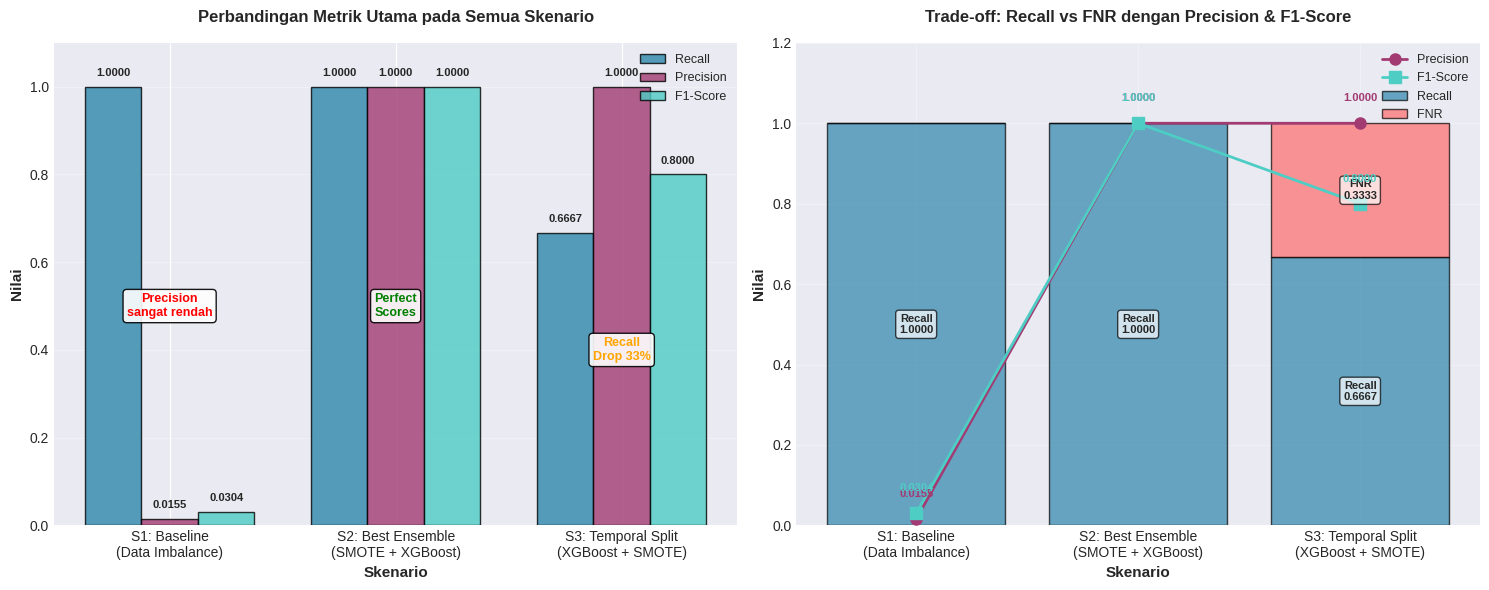

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Set style
plt.style.use('seaborn-v0_8-darkgrid')

# Data dari hasil eksperimen
scenarios_data = {
    'Scenario': ['S1: Baseline\n(Data Imbalance)', 'S2: Best Ensemble\n(SMOTE + XGBoost)', 'S3: Temporal Split\n(XGBoost + SMOTE)'],
    'Recall': [1.0000, 1.0000, 0.6667],
    'Precision': [0.0155, 1.0000, 1.0000],
    'F1-Score': [0.0304, 1.0000, 0.8000],
    'FNR': [0.0000, 0.0000, 0.3333],
    'ROC-AUC': [0.9907, 1.0000, 0.9996]
}

scenarios_df = pd.DataFrame(scenarios_data)

# ============================================================
# VISUALISASI 1: GROUPED BAR CHART - Semua Metrik
# ============================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Subplot 1: Grouped Bar Chart untuk Recall, Precision, F1-Score
x = np.arange(len(scenarios_df['Scenario']))
width = 0.25

bars1 = ax1.bar(x - width, scenarios_df['Recall'], width,
                label='Recall', color='#2E86AB', alpha=0.8, edgecolor='black')
bars2 = ax1.bar(x, scenarios_df['Precision'], width,
                label='Precision', color='#A23B72', alpha=0.8, edgecolor='black')
bars3 = ax1.bar(x + width, scenarios_df['F1-Score'], width,
                label='F1-Score', color='#4ECDC4', alpha=0.8, edgecolor='black')

ax1.set_xlabel('Skenario', fontsize=11, fontweight='bold')
ax1.set_ylabel('Nilai', fontsize=11, fontweight='bold')
ax1.set_title('Perbandingan Metrik Utama pada Semua Skenario',
              fontsize=12, fontweight='bold', pad=15)
ax1.set_xticks(x)
ax1.set_xticklabels(scenarios_df['Scenario'], fontsize=10)
ax1.legend(loc='upper right', fontsize=9)
ax1.grid(True, alpha=0.3, axis='y')
ax1.set_ylim([0, 1.1])

# Tambah nilai di atas bar
for bars, values in zip([bars1, bars2, bars3],
                        [scenarios_df['Recall'], scenarios_df['Precision'], scenarios_df['F1-Score']]):
    for bar, val in zip(bars, values):
        height = bar.get_height()
        ax1.text(bar.get_x() + bar.get_width()/2., height + 0.02,
                f'{val:.4f}', ha='center', va='bottom',
                fontsize=8, fontweight='bold')

# Tambah anotasi penting
ax1.text(0, 0.5, 'Precision\nsangat rendah',
         ha='center', va='center', fontsize=9, color='red', fontweight='bold',
         bbox=dict(boxstyle='round', facecolor='white', alpha=0.9))
ax1.text(1, 0.5, 'Perfect\nScores',
         ha='center', va='center', fontsize=9, color='green', fontweight='bold',
         bbox=dict(boxstyle='round', facecolor='white', alpha=0.9))
ax1.text(2, 0.4, 'Recall\nDrop 33%',
         ha='center', va='center', fontsize=9, color='orange', fontweight='bold',
         bbox=dict(boxstyle='round', facecolor='white', alpha=0.9))

# Subplot 2: Stacked Bar untuk Trade-off dan FNR
ax2.bar(scenarios_df['Scenario'], scenarios_df['Recall'],
        label='Recall', color='#2E86AB', alpha=0.7, edgecolor='black')
ax2.bar(scenarios_df['Scenario'], scenarios_df['FNR'],
        bottom=scenarios_df['Recall'],
        label='FNR', color='#FF6B6B', alpha=0.7, edgecolor='black')

# Tambah line untuk Precision dan F1-Score
ax2.plot(scenarios_df['Scenario'], scenarios_df['Precision'],
         'o-', linewidth=2, markersize=8, label='Precision', color='#A23B72')
ax2.plot(scenarios_df['Scenario'], scenarios_df['F1-Score'],
         's-', linewidth=2, markersize=8, label='F1-Score', color='#4ECDC4')

ax2.set_xlabel('Skenario', fontsize=11, fontweight='bold')
ax2.set_ylabel('Nilai', fontsize=11, fontweight='bold')
ax2.set_title('Trade-off: Recall vs FNR dengan Precision & F1-Score',
              fontsize=12, fontweight='bold', pad=15)
ax2.legend(loc='upper right', fontsize=9)
ax2.grid(True, alpha=0.3)
ax2.set_ylim([0, 1.2])

# Tambah nilai pada plot
for idx, scenario in enumerate(scenarios_df['Scenario']):
    # Nilai Recall + FNR (stacked)
    recall_val = scenarios_df.loc[idx, 'Recall']
    fnr_val = scenarios_df.loc[idx, 'FNR']
    ax2.text(idx, recall_val/2, f'Recall\n{recall_val:.4f}',
             ha='center', va='center', fontsize=8, fontweight='bold',
             bbox=dict(boxstyle='round', facecolor='white', alpha=0.7))

    if fnr_val > 0:
        ax2.text(idx, recall_val + fnr_val/2, f'FNR\n{fnr_val:.4f}',
                 ha='center', va='center', fontsize=8, fontweight='bold',
                 bbox=dict(boxstyle='round', facecolor='white', alpha=0.7))

    # Nilai Precision
    prec_val = scenarios_df.loc[idx, 'Precision']
    ax2.text(idx, prec_val + 0.05, f'{prec_val:.4f}',
             ha='center', va='bottom', fontsize=8, fontweight='bold', color='#A23B72')

    # Nilai F1-Score
    f1_val = scenarios_df.loc[idx, 'F1-Score']
    ax2.text(idx, f1_val + 0.05, f'{f1_val:.4f}',
             ha='center', va='bottom', fontsize=8, fontweight='bold', color='#4ECDC4')

plt.tight_layout()
plt.show()